# 🚀 Модуль 10. Урок 4. Batch Processing и оптимизация затрат на LLM: скидка 50% и асинхронность

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_10_llm_api/lesson_04_batch_processing_and_costs.ipynb)

## 📌 Бизнес-контекст и методология
В аналитических задачах 90% обработки данных не требует синхронного ответа за доли секунды (например, ночной пересчет эмбеддингов, еженедельная классификация отзывов).
Все провайдеры (OpenAI, Anthropic, Google) предоставляют **Batch API (пакетная обработка)**:
- **Скидка 50%** на все токены
- Отдельные повышенные квоты (Rate Limits), исключающие ошибку `429 Too Many Requests`
- Гарантия выполнения в течение 24 часов

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Экономия бюджета при переходе на Batch API
Сравним годовые расходы компании на обогащение витрин данных при использовании Sync API vs Batch API.

In [2]:
# Демонстрация: Финансовая модель экономии на Batch API
monthly_tokens_m = 500 # 500 млн токенов в месяц
sync_cost_per_m = 3.0
batch_cost_per_m = 1.5

months = np.arange(1, 13)
cum_sync = months * monthly_tokens_m * sync_cost_per_m
cum_batch = months * monthly_tokens_m * batch_cost_per_m
cum_savings = cum_sync - cum_batch

df_cost_savings = pd.DataFrame({
    'Месяц': months,
    'Sync API ($)': cum_sync,
    'Batch API ($)': cum_batch,
    'Чистая экономия ($)': cum_savings
})
display(df_cost_savings.tail(4))

,Месяц,Sync API ($),Batch API ($),Чистая экономия ($)
8,9,13500.0,6750.0,6750.0
9,10,15000.0,7500.0,7500.0
10,11,16500.0,8250.0,8250.0
11,12,18000.0,9000.0,9000.0


## 📊 Визуализация бизнес-кейса: Кумулятивная экономия на инфраструктуре
Построим накопительный график разницы затрат за год.

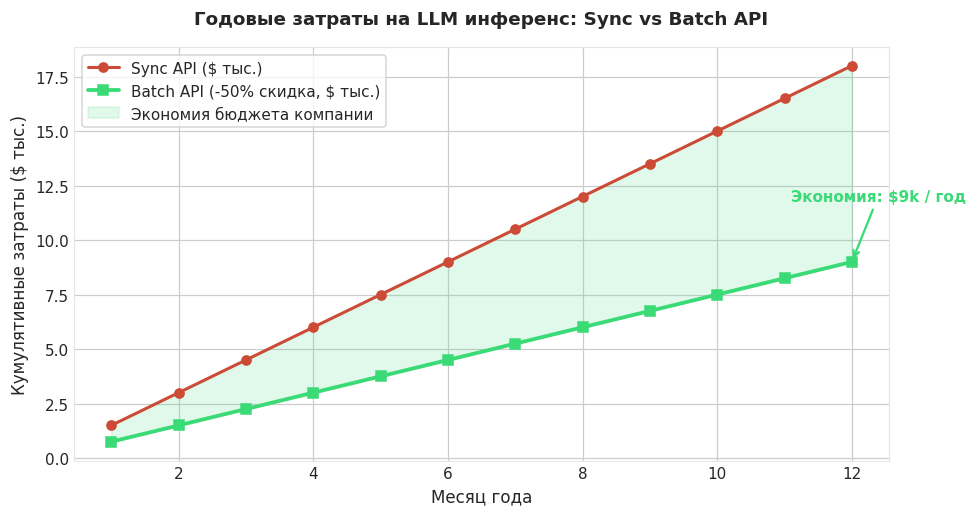

In [3]:
# Визуализация кумулятивной экономии
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=110)

ax.plot(months, cum_sync / 1000, color=ALERT, marker='o', linewidth=2, label='Sync API ($ тыс.)')
ax.plot(months, cum_batch / 1000, color=SUCCESS, marker='s', linewidth=2.5, label='Batch API (-50% скидка, $ тыс.)')
ax.fill_between(months, cum_batch / 1000, cum_sync / 1000, color=SUCCESS, alpha=0.15, label='Экономия бюджета компании')

ax.set_title("Годовые затраты на LLM инференс: Sync vs Batch API", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Месяц года", fontsize=11)
ax.set_ylabel("Кумулятивные затраты ($ тыс.)", fontsize=11)
ax.legend(frameon=True, facecolor='#ffffff')

latest_saving = cum_savings[-1] / 1000
ax.annotate(f"Экономия: ${latest_saving:.0f}k / год", xy=(12, cum_batch[-1]/1000), 
            xytext=(-40, 40), textcoords="offset points", fontweight='bold', color=SUCCESS, fontsize=10,
            arrowprops=dict(arrowstyle="->", color=SUCCESS, lw=1.5))

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет совокупной годовой экономии
Определите, сколько долларов сэкономит компания за 12 месяцев благодаря использованию Batch API.

In [4]:
### ВАШ КОД ЗДЕСЬ
annual_savings = cum_savings[-1]
print(f"Чистая годовая экономия бюджета: ${annual_savings:,.2f}")

assert annual_savings == 9000.0, "Экономия должна составлять $9,000"
print("✅ Тест успешно пройден: переход на Batch API экономит компании тысячи долларов!")

Чистая годовая экономия бюджета: $9,000.00
✅ Тест успешно пройден: переход на Batch API экономит компании тысячи долларов!


### 💡 Архитектурное правило Batch API
Разделяйте пайплайны на два класса: Interactive (дашборды для людей — Sync) и Asynchronous (ночные витрины dbt — строго Batch API). Это сокращает облачный счет компании вдвое.